In [140]:
from google.colab import files
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

In [82]:
# Load transfers data
d1 = files.upload()
transfers = pd.read_csv('TRANSFERS.csv')

Saving TRANSFERS.csv to TRANSFERS (1).csv


In [83]:
# Load admissions data
d2 = files.upload()
admissions = pd.read_csv('ADMISSIONS.csv')

Saving ADMISSIONS.csv to ADMISSIONS (1).csv


In [84]:
# Load D_CPT data
d4 = files.upload()
d_cpt = pd.read_csv('D_CPT.csv')

Saving D_CPT.csv to D_CPT (1).csv


In [85]:
# Load note caregivers data
d4 = files.upload()
caregivers = pd.read_csv('CAREGIVERS.csv')

Saving CAREGIVERS.csv to CAREGIVERS (1).csv


In [86]:
# Load note drug codes data
d4 = files.upload()
drg = pd.read_csv('DRGCODES.csv')

Saving DRGCODES.csv to DRGCODES (1).csv


In [141]:
#Plot 1 - Transfers by Current Care Unit

transfer_counts = transfers['CURR_CAREUNIT'].value_counts().reset_index()

transfer_counts.columns = ['care_unit', 'count']

fig1 = px.bar(

    transfer_counts,

    x='care_unit',

    y='count',

    color='care_unit',

    title='Transfers by Current Care Unit',

    color_discrete_sequence=px.colors.qualitative.Vivid

)

fig1.update_layout(

    xaxis_title='Current Care Unit',

    yaxis_title='Number of Transfers',

    showlegend=False,

    xaxis_tickangle=-45

)

fig1.show()

<ipython-input-147-aaac65737a8b>:5: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




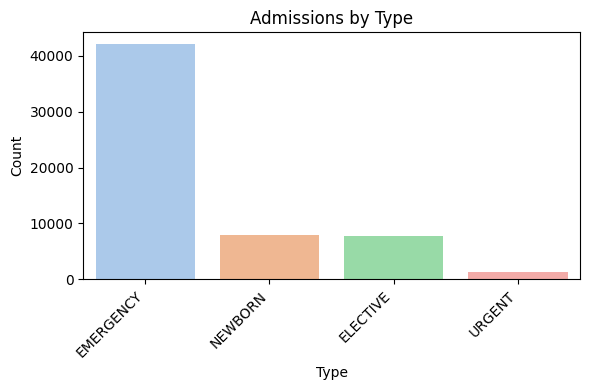

In [147]:
#Plot 2 - Admissions by Type

plt.figure(figsize=(6,4))

sns.countplot(

    x='ADMISSION_TYPE',

    data=admissions,

    order=admissions['ADMISSION_TYPE'].value_counts().index,

    palette='pastel'

)

plt.title('Admissions by Type')

plt.xlabel('Type')

plt.ylabel('Count')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.show()

In [129]:
#Plot 3 - Caregivers by Role

care_counts = caregivers['LABEL'].value_counts().reset_index()

care_counts.columns = ['role', 'count']

fig3 = px.pie(

    care_counts,

    names='role',

    values='count',

    title='Caregivers by Role',

    color_discrete_sequence=px.colors.sequential.Plasma

)

fig3.update_traces(textposition='inside', textinfo='percent+label')

fig3.show()

In [128]:
#Plot 4 - CPT Codes by Section Header

section_counts = d_cpt['SECTIONHEADER'].value_counts().reset_index()

section_counts.columns = ['section', 'count']

source_cpt = ColumnDataSource(section_counts)


p2 = figure(

    x_range=section_counts['section'].tolist(),

    title='CPT Codes by Section Header',

    height=300,

    sizing_mode='stretch_width',

    background_fill_color='#f0f0f0'

)

p2.vbar(x='section', top='count', width=0.7, source=source_cpt, color='orange')

p2.xaxis.major_label_orientation = 1.2

p2.xaxis.axis_label = 'Section Header'

p2.yaxis.axis_label = 'Number of Codes'

show(p2)

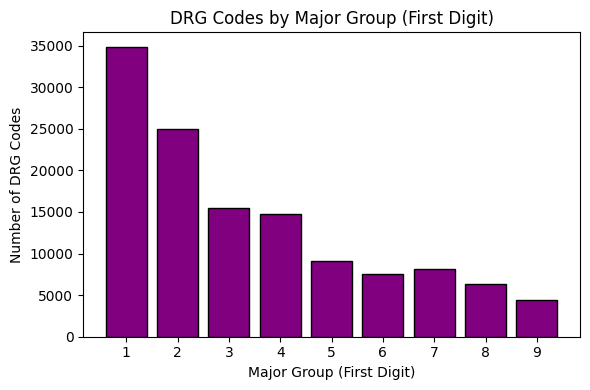

In [127]:
#Plot 5 - DRG Codes by Major Group

drg['major_group'] = drg['DRG_CODE'].astype(str).str[0]

drg_counts = drg['major_group'].value_counts().sort_index()

plt.figure(figsize=(6,4))

plt.bar(drg_counts.index, drg_counts.values, color='purple', edgecolor='black')

plt.title('DRG Codes by Major Group (First Digit)')

plt.xlabel('Major Group (First Digit)')

plt.ylabel('Number of DRG Codes')

plt.tight_layout()

plt.show()